# 06 — Feature Selection

[Previous](./05_Feature_Engineering.ipynb) | [Repository guide](../README.md) | [Next](./07_Dimensionality_Reduction.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** test whether a smaller feature set can keep the improvement from notebook 05.

`solution.csv` is never read. Selection that uses the target stays inside each validation fold.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
from functools import partial

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_backend
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel, SelectKBest, VarianceThreshold, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. What is feature selection?

Feature engineering **creates** candidates; feature selection **keeps or removes** inputs.

1. Preprocessing turns raw columns into model columns.
2. A selector decides which columns survive.
3. Logistic regression trains only on the survivors.

- A **filter** scores a feature before the final model, such as variance or mutual information.
- An **embedded selector** chooses features while fitting a model, such as L1 logistic regression.
- **Ablation** removes a known group and checks whether validation improves.

Selection can make a model smaller and clearer, but a low correlation alone never proves that a feature is useless.


## 2. Methods to compare

| Method | Beginner meaning | Main risk |
|---|---|---|
| All engineered | Keep every original and engineered input | Largest and least selective |
| Remove known decoys | Post-competition ablation of organizer-created noise columns | Knowledge is specific to this competition |
| Match-state compact | Keep non-decoys plus one small idea group | Can omit weaker real signals |
| Variance filter | Remove encoded columns that never change | Usually removes little |
| Mutual information top 20 | Keep the 20 columns with strongest dependency on the target | Ranking can vary by fold |
| L1 embedded | Push weak logistic coefficients to exactly zero | Depends on regularization strength |


In [4]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    # Relative-ability hypotheses.
    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    # Match state: whether the kicker's team is leading, tied, or losing.
    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    # Post-competition reconstruction of the problem's pressure idea.
    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    # Interactions: one condition changes the effect of another.
    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    # Generic suggested candidates: useful to test even when the result rejects them.
    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    # Composure is hidden; skill_proxy is a visible, imperfect substitute.
    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result

KNOWN_DECOYS = ["jersey_color", "referee_strictness", "stadium_capacity", "temperature", "weather_humidity"]
all_engineered = []
for group_columns in FEATURE_GROUPS.values():
    all_engineered.extend(group_columns)
X_original = train.drop(columns=[TARGET] + ID_COLUMNS)
X = add_engineered_features(X_original)
y = train[TARGET].astype(int)


### From the top-1 plots to a decoy-removal experiment

The top-1 notebook used correlations and scoring-rate plots to suspect `jersey_color` and `referee_strictness`. In this post-competition solution we know five columns were generated as decoys. The plot below shows their weak one-feature relationship, but the real test is the OOF ablation named **Remove known decoys**.


,feature,measure,univariate_signal
1,referee_strictness,absolute correlation,0.0015
4,weather_humidity,absolute correlation,0.0286
0,jersey_color,category scoring-rate range,0.0371
2,stadium_capacity,absolute correlation,0.0631
3,temperature,absolute correlation,0.0727


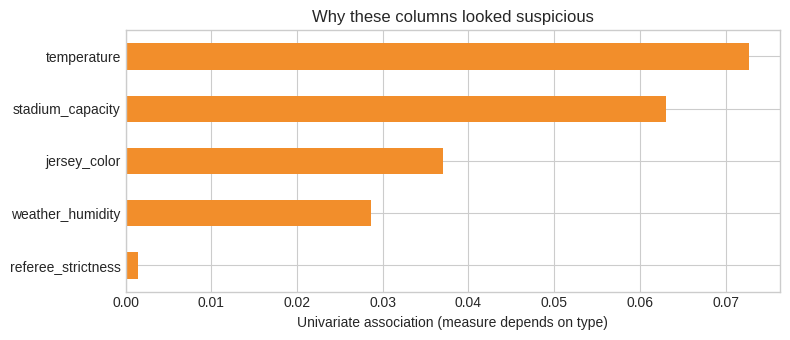

Low univariate signal creates a removal hypothesis; cross-validation decides whether removal is safe.


In [5]:
decoy_evidence = []
for column in KNOWN_DECOYS:
    if pd.api.types.is_numeric_dtype(train[column]):
        value = abs(train[[column, TARGET]].corr(numeric_only=True).iloc[0, 1])
        measure = "absolute correlation"
    else:
        rates = train.groupby(column, dropna=False)[TARGET].mean()
        value = rates.max() - rates.min()
        measure = "category scoring-rate range"
    decoy_evidence.append({"feature": column, "measure": measure, "univariate_signal": value})

decoy_evidence = pd.DataFrame(decoy_evidence).sort_values("univariate_signal")
display(decoy_evidence)
ax = decoy_evidence.plot.barh(x="feature", y="univariate_signal", legend=False, figsize=(8, 3.5), color="#f28e2b")
ax.set(title="Why these columns looked suspicious", xlabel="Univariate association (measure depends on type)", ylabel="")
plt.tight_layout()
plt.show()
print("Low univariate signal creates a removal hypothesis; cross-validation decides whether removal is safe.")


## 3. Leakage-safe comparison

The imputer, encoder, scaler, and selector are one pipeline. During cross-validation, each selector sees only that fold’s training rows. This prevents **selection leakage**: using validation targets to decide which features survive.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_pipeline(selected_columns, selector):
    numerical_columns = X[selected_columns].select_dtypes(include=np.number).columns.tolist()
    categorical_columns = [column for column in selected_columns if column not in numerical_columns]
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("selector", selector),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ])


base_columns = X_original.columns.tolist()
all_columns = base_columns + all_engineered
non_decoy_base = [column for column in base_columns if column not in KNOWN_DECOYS]

experiments = [
    ("All engineered", all_columns, "passthrough"),
    ("Remove known decoys", non_decoy_base + all_engineered, "passthrough"),
    ("Match-state compact", non_decoy_base + FEATURE_GROUPS["Match state"], "passthrough"),
    ("Variance filter", all_columns, VarianceThreshold(threshold=0.0)),
    ("Mutual information top 20", all_columns, SelectKBest(
        score_func=partial(mutual_info_classif, random_state=RANDOM_STATE), k=20
    )),
    ("L1 embedded selection", all_columns, SelectFromModel(
        LogisticRegression(
            penalty="l1", solver="liblinear", C=0.5,
            max_iter=5000, random_state=RANDOM_STATE,
        ), threshold="median",
    )),
]


In [7]:
rows = []
selection_details = {}

for name, selected_columns, selector in experiments:
    pipeline = make_pipeline(selected_columns, selector)

    with parallel_backend("threading"):
        probabilities = cross_val_predict(
            pipeline, X[selected_columns], y, cv=cv,
            method="predict_proba", n_jobs=-1,
        )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)
    fold_f1 = [f1_score(y.iloc[index], predictions[index]) for _, index in cv.split(X, y)]

    pipeline.fit(X[selected_columns], y)
    feature_names = np.asarray(pipeline.named_steps["preprocessor"].get_feature_names_out())
    fitted_selector = pipeline.named_steps["selector"]
    support = np.ones(len(feature_names), dtype=bool) if fitted_selector == "passthrough" else fitted_selector.get_support()
    kept_names = feature_names[support].tolist()
    selection_details[name] = {"all": feature_names.tolist(), "kept": kept_names}

    rows.append({
        "method": name,
        "input_columns": len(selected_columns),
        "selected_features": int(support.sum()),
        "f1": f1_score(y, predictions),
        "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
    })

results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(results)


,method,input_columns,selected_features,f1,f1_std,precision,recall,accuracy,roc_auc
0,L1 embedded selection,49,33,0.8851,0.0083,0.8913,0.8790,0.8973,0.9622
1,All engineered,49,66,0.8847,0.0061,0.8916,0.8779,0.8970,0.9625
2,Variance filter,49,66,0.8847,0.0061,0.8916,0.8779,0.8970,0.9625
3,Remove known decoys,44,54,0.8837,0.0085,0.8906,0.8769,0.8961,0.9618
4,Match-state compact,18,28,0.8719,0.0075,0.8802,0.8638,0.8858,0.9553
5,Mutual information top 20,49,20,0.8543,0.0071,0.8650,0.8439,0.8705,0.9458


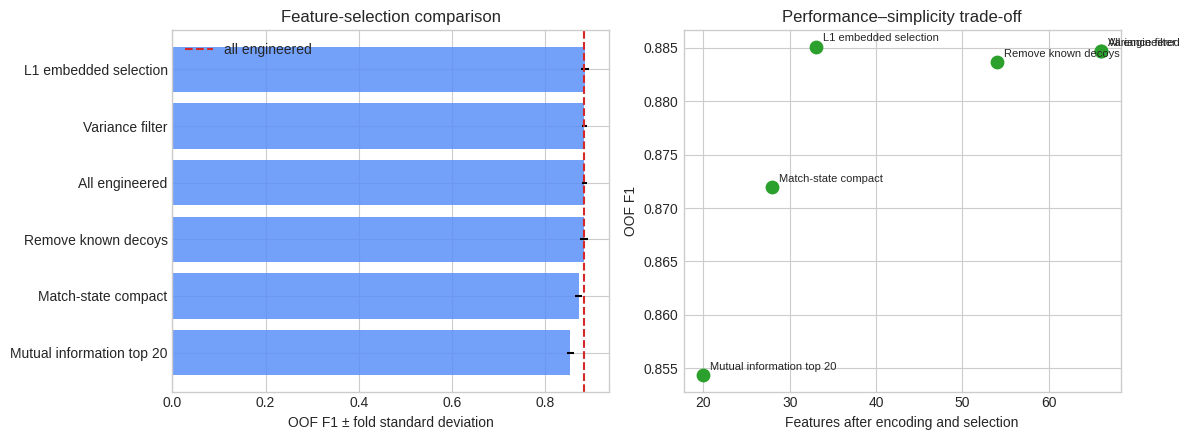

In [8]:
reference = results.loc[results["method"].eq("All engineered")].iloc[0]
ordered = results.sort_values("f1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(ordered["method"], ordered["f1"], xerr=ordered["f1_std"], color="#5b8ff9", alpha=.85)
axes[0].axvline(reference["f1"], color="#d62728", linestyle="--", label="all engineered")
axes[0].set(title="Feature-selection comparison", xlabel="OOF F1 ± fold standard deviation", ylabel="")
axes[0].legend()

axes[1].scatter(results["selected_features"], results["f1"], s=80, color="#2ca02c")
for _, row in results.iterrows():
    axes[1].annotate(row["method"], (row["selected_features"], row["f1"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
axes[1].set(title="Performance–simplicity trade-off", xlabel="Features after encoding and selection", ylabel="OOF F1")
plt.tight_layout()
plt.show()


### Concrete dataset example: which columns survived?

The first chart counted features; this one names them. Coefficients are shown after imputation, scaling, and one-hot encoding, so larger absolute bars mean a stronger logistic effect—not causality.


L1 embedded selection kept 33 encoded features and removed 33.
First kept features: ['num__stadium_capacity', 'num__temperature', 'num__minute_taken', 'num__goalkeeper_last5_saved_percent', 'num__strong_foot_usage', 'num__weak_foot_usage', 'num__foot_difference', 'num__is_close_game', 'num__is_winning', 'num__match_status', 'num__home_crowd_aligned', 'num__is_poor_pitch']
First removed features: ['cat__home_or_away_Neutral', 'cat__jersey_color_Black', 'cat__jersey_color_Blue', 'cat__jersey_color_Green', 'cat__jersey_color_Orange', 'cat__jersey_color_Purple', 'cat__jersey_color_Red', 'cat__jersey_color_White', 'cat__jersey_color_Yellow', 'cat__match_type_Friendly', 'cat__match_type_League', 'cat__pitch_condition_Good']


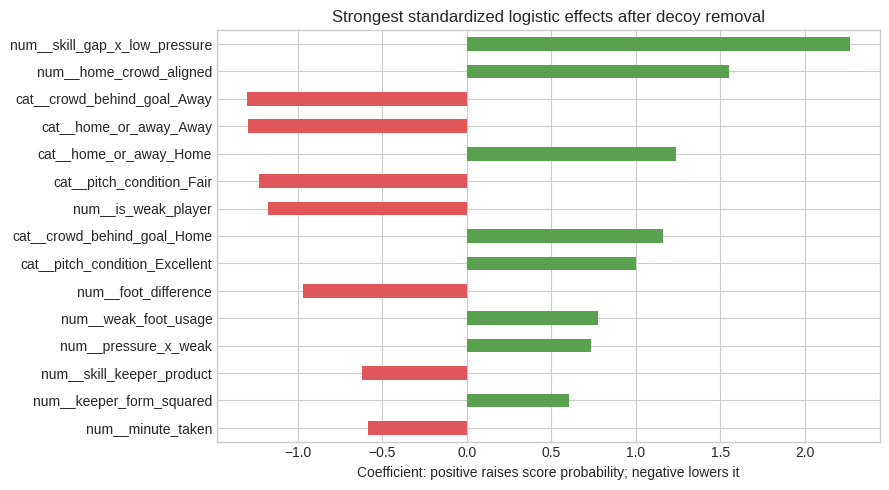

In [9]:
example_selector = "L1 embedded selection"
kept = selection_details[example_selector]["kept"]
removed = sorted(set(selection_details[example_selector]["all"]) - set(kept))
print(f"{example_selector} kept {len(kept)} encoded features and removed {len(removed)}.")
print("First kept features:", kept[:12])
print("First removed features:", removed[:12])

explanation_model = make_pipeline(non_decoy_base + all_engineered, "passthrough")
explanation_model.fit(X[non_decoy_base + all_engineered], y)
explanation_names = explanation_model.named_steps["preprocessor"].get_feature_names_out()
coefficient_table = pd.DataFrame({
    "feature": explanation_names,
    "coefficient": explanation_model.named_steps["model"].coef_[0],
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
top_coefficients = coefficient_table.nlargest(15, "absolute_coefficient").sort_values("absolute_coefficient")

ax = top_coefficients.plot.barh(
    x="feature", y="coefficient", legend=False, figsize=(9, 5),
    color=np.where(top_coefficients["coefficient"] >= 0, "#59a14f", "#e15759"),
    title="Strongest standardized logistic effects after decoy removal",
)
ax.set(xlabel="Coefficient: positive raises score probability; negative lowers it", ylabel="")
plt.tight_layout()
plt.show()


## 4. How the decision is made

The dashed score is the all-engineered reference. The second chart asks: how many encoded inputs can we remove before F1 falls outside ordinary fold variation?

The **one-standard-error idea** prefers a smaller method when its F1 remains within one fold standard deviation of the reference. It is a simplicity rule, not a claim that every removed feature is useless.


In [10]:
minimum_acceptable = reference["f1"] - reference["f1_std"]
eligible = results.loc[results["f1"] >= minimum_acceptable]
choice = eligible.sort_values(["selected_features", "f1"], ascending=[True, False]).iloc[0]

print(f"All-engineered reference: F1 {reference['f1']:.4f} with {int(reference['selected_features'])} encoded features")
print(f"Acceptable range starts at: {minimum_acceptable:.4f}")
print(f"Simplest method in that range: {choice['method']} | F1 {choice['f1']:.4f} | {int(choice['selected_features'])} features")
print("Decision: carry the simplest near-best method into the model-comparison notebook.")


All-engineered reference: F1 0.8847 with 66 encoded features
Acceptable range starts at: 0.8786
Simplest method in that range: L1 embedded selection | F1 0.8851 | 33 features
Decision: carry the simplest near-best method into the model-comparison notebook.


## Other alternatives

- **Correlation removal:** drops one of two strongly related numerical features; fast, but a linear correlation misses nonlinear redundancy.
- **ANOVA F-test:** ranks numerical features by linear class separation; simple, but assumes a particular relationship.
- **Chi-square selection:** tests nonnegative count-like features against the class; scaling here creates negative values, so it is not run.
- **Recursive Feature Elimination (RFE):** repeatedly fits a model and removes weak features; thorough but slow.
- **RFECV:** uses cross-validation to choose the RFE size; much more expensive because it nests many fits.
- **Sequential selection:** adds or removes one feature at a time; intuitive but slow and greedy.
- **Tree importance / permutation importance:** rank features after fitting a model; useful later when tree models are compared.
- **Boruta:** keeps features that beat randomized shadow features; robust, but designed around tree models and extra computation.

In [11]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "06_feature_selection.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")


Saved: /kaggle/working/06_feature_selection.csv


## Why the feature-selection decision is justified

**Technical evidence:** decoy removal is tested as an OOF ablation, learned selectors operate inside each fold, and the chosen method preserves F1 within the reference’s normal fold variation while using fewer inputs.

**Theoretical reason:** weak or redundant columns can add noise and interpretation cost, but aggressive removal can discard joint signal. We therefore choose the smallest near-best validated set, not the smallest possible set and not a list chosen from correlation alone.
